# Лабораторная работа по pandas


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## Эпизод 1. Платежи

**Задача 1.** Найти три самых крупных проведённых платежа (`STATUS == 'OK'`).

In [2]:
transactions = pd.read_csv('transactions.csv', index_col=0)
ok = transactions[transactions['STATUS'] == 'OK']

display(ok.nlargest(3, 'SUM'))

,CONTRACTOR,STATUS,SUM
5085,"Acme, Inc",OK,100500
4451,"Umbrella, Inc",OK,1000
336,"Acme, Inc",OK,999


**Задача 2.** Вычислить общую сумму проведённых платежей в адрес Umbrella, Inc.

In [3]:
total = ok.loc[ok['CONTRACTOR'] == 'Umbrella, Inc', 'SUM'].sum()
print('Сумма платежей Umbrella, Inc:', total)

Сумма платежей Umbrella, Inc: 925719


## Эпизод 2. Грузовые рейсы

Для каждой авиакомпании считаем число рейсов, суммарную стоимость и суммарную массу грузов.

In [4]:
flights = pd.read_csv('flights.csv', index_col=0)

summary = flights.groupby('CARGO').agg(
    Рейсы=('CARGO', 'size'),
    Стоимость=('PRICE', 'sum'),
    Масса=('WEIGHT', 'sum')
)
display(summary)

,Рейсы,Стоимость,Масса
CARGO,,,
Jumbo,50,76795,18709
Medium,100,36312,9507
Nimble,500,752588,7545


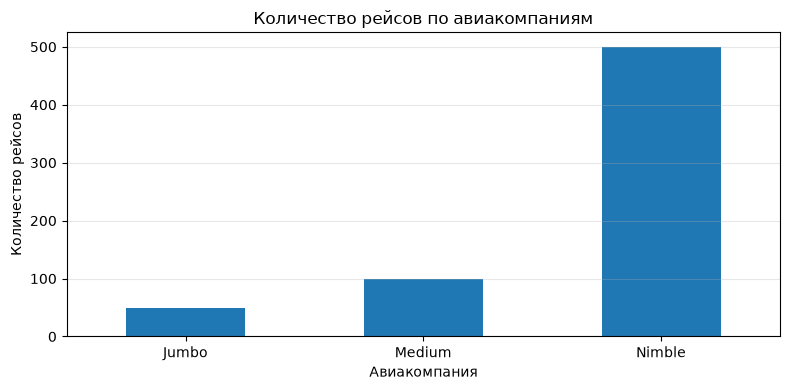

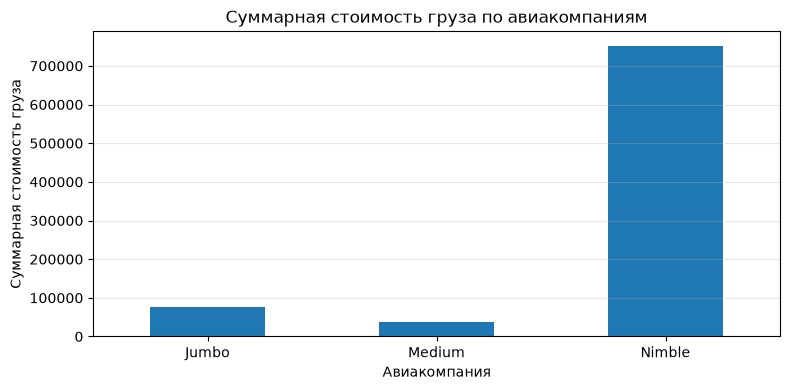

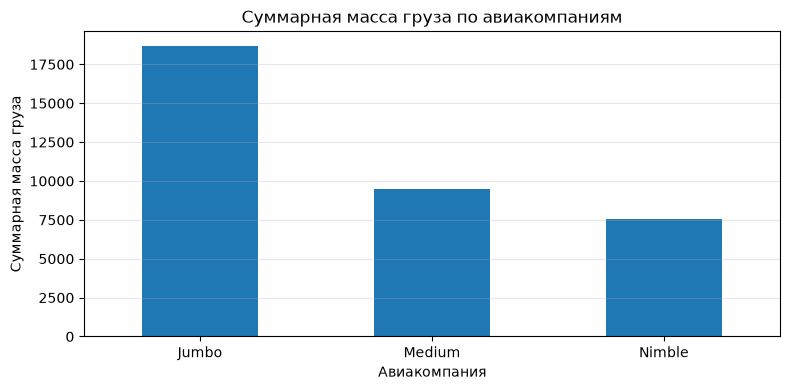

In [5]:
for column, ylabel in [
    ('Рейсы', 'Количество рейсов'),
    ('Стоимость', 'Суммарная стоимость груза'),
    ('Масса', 'Суммарная масса груза')
]:
    ax = summary[column].plot.bar(figsize=(8, 4), rot=0)
    ax.set_title(ylabel + ' по авиакомпаниям')
    ax.set_xlabel('Авиакомпания')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

## Эпизод 3. Входное тестирование

В Excel логины находятся в столбце `login`, а в таблице ejudge — в столбце `User`. Объединяем их по логинам.

In [6]:
students = pd.read_excel('students_info.xlsx')
results = pd.read_html('results_ejudge.html')[0]
results = results.rename(columns={'User': 'login'})

print('Студенты:', len(students), '| Результаты ejudge:', len(results))
display(results.head())

Студенты: 116 | Результаты ejudge: 129


,Place,login,A,B,C,D,E,F,G,H,Solved,Score
0,1,r0300205,9.0,10.0,19.0,20.0,20.0,30.0,30.0,49.0,8,187
1,2,r0300206,10.0,3.0,20.0,20.0,20.0,30.0,30.0,49.0,7,182
2,3,r0300508,10.0,10.0,20.0,20.0,20.0,30.0,29.0,NaN,7,139
3,4,r0300314,9.0,9.0,20.0,20.0,20.0,30.0,9.0,20.0,6,137
4,5,r0300209,8.0,10.0,14.0,20.0,20.0,30.0,0.0,30.0,5,132


### Задача 1. Среднее количество решённых задач

Используем готовый столбец `Solved` из ejudge. Студенты из Excel, для которых результат не найден, учитываются с нулём решённых задач.

In [7]:
data = students.merge(results[['login', 'Solved']], on='login', how='left')
data['Solved'] = data['Solved'].fillna(0)

faculty = data.groupby('group_faculty')['Solved'].mean()
informatics = data.groupby('group_out')['Solved'].mean()

print('По факультетским группам:')
display(faculty.to_frame('Среднее число задач'))
print('По группам информатики:')
display(informatics.to_frame('Среднее число задач'))

По факультетским группам:


,Среднее число задач
group_faculty,
1,0.588235
2,2.187500
3,1.312500
4,2.066667
5,2.000000
6,1.444444
8,0.812500


По группам информатики:


,Среднее число задач
group_out,
31,0.200000
32,0.000000
33,5.500000
34,0.000000
35,2.222222
36,1.526316
38,0.812500


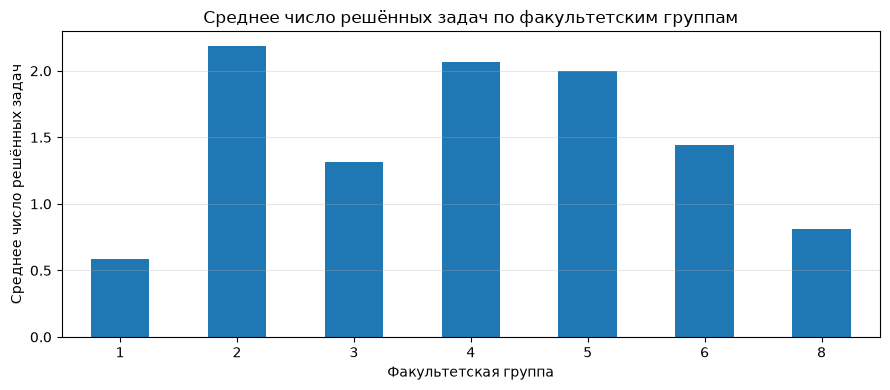

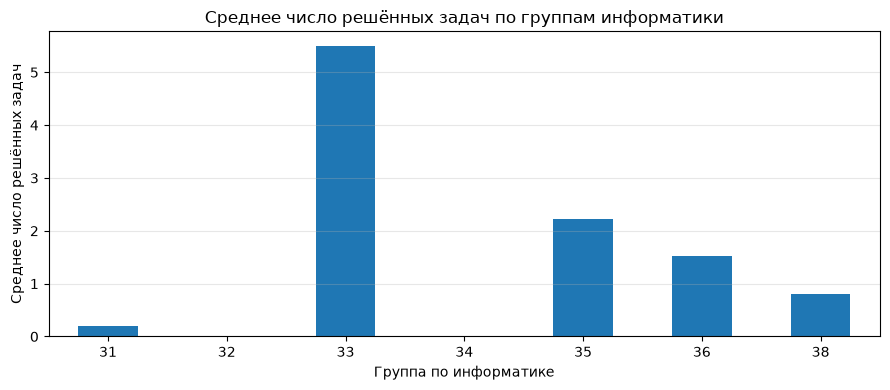

In [8]:
for values, title, xlabel in [
    (faculty, 'Среднее число решённых задач по факультетским группам', 'Факультетская группа'),
    (informatics, 'Среднее число решённых задач по группам информатики', 'Группа по информатике')
]:
    ax = values.plot.bar(figsize=(9, 4), rot=0)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Среднее число решённых задач')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

### Задача 2. Более одного пройденного теста в G или H

За тест дают 10 баллов, поэтому условие: **`G > 10` или `H > 10`**. Найдём студентов и их распределение по группам.

In [9]:
passed = results[(results['G'] > 10) | (results['H'] > 10)]
selected = students.merge(passed[['login', 'G', 'H']], on='login', how='inner')

print('Количество студентов:', len(selected))
display(selected[['login', 'group_faculty', 'group_out', 'G', 'H']])

print('По факультетским группам:')
display(selected.groupby('group_faculty').size().to_frame('Количество'))

print('По группам информатики:')
display(selected.groupby('group_out').size().to_frame('Количество'))

print('Переходы между группами:')
display(pd.crosstab(selected['group_faculty'], selected['group_out']))

Количество студентов: 11


,login,group_faculty,group_out,G,H
0,r0300205,2,33,30.0,49.0
1,r0300206,2,33,30.0,49.0
2,r0300209,2,33,0.0,30.0
3,r0300212,2,36,NaN,20.0
4,r0300301,3,35,8.0,23.0
5,r0300314,3,33,9.0,20.0
6,r0300414,4,33,NaN,15.0
7,r0300508,5,33,29.0,NaN
8,r0300511,5,35,NaN,29.0
9,r0300514,5,33,NaN,30.0


По факультетским группам:


,Количество
group_faculty,
2,4
3,2
4,1
5,4


По группам информатики:


,Количество
group_out,
33,7
35,3
36,1


Переходы между группами:


group_out,33,35,36
group_faculty,,,
2,3,0,1
3,1,1,0
4,1,0,0
5,2,2,0


### Дополнительное задание. Нестыковки в исходных данных

Проверим отсутствие логинов, повторы и логины, которые встречаются только в одной из двух таблиц.

In [10]:
excel_logins = set(students['login'].dropna())
ejudge_logins = set(results['login'].dropna())

print('Пустых логинов в Excel:', students['login'].isna().sum())
print('Повторных непустых логинов в Excel:', students['login'].dropna().duplicated().sum())
print('Повторных логинов в ejudge:', results['login'].duplicated().sum())
print('Совпадающих логинов:', len(excel_logins & ejudge_logins))
print('Только в Excel:', len(excel_logins - ejudge_logins))
print('Только в ejudge:', len(ejudge_logins - excel_logins))

display(pd.DataFrame({'Логины только в ejudge': sorted(ejudge_logins - excel_logins)}))
display(students[students['login'].isna()])

Пустых логинов в Excel: 6
Повторных непустых логинов в Excel: 0
Повторных логинов в ejudge: 0
Совпадающих логинов: 110
Только в Excel: 0
Только в ejudge: 19


,Логины только в ejudge
0,r0300117
1,r0300118
2,r0300120
3,r0300217
4,r0300218
5,r0300317
6,r0300318
7,r0300408
8,r0300416
9,r0300417


,login,group_faculty,group_out
110,NaN,4,31
111,NaN,8,38
112,NaN,8,38
113,NaN,8,38
114,NaN,8,38
115,NaN,8,38
